MSSP6070 Assignment 1: Academic Performance of Engineering Students


Upload data_academic_performance.xlsx to the Colab files pane, then run all cells.

Source: De La Hoz, Enrique. “Data of Academic Performance Evolution for Engineering Students.” Mendeley Data, version 1, 2020, https://doi.org/10.17632/83tcx8psxv.1.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from IPython.display import display

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', None)

DATA_PATH = 'data_academic_performance.xlsx'

import os
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()   # choose data_academic_performance.xlsx

xl = pd.ExcelFile(DATA_PATH)
print(xl.sheet_names)
df = pd.read_excel(xl, sheet_name='SABER11_SABERPRO')
print(df.shape)
df.head()

Saving data_academic_performance.xlsx to data_academic_performance.xlsx
['Citation', 'Description of Categorical', 'Description of Numerical', 'SABER11_SABERPRO']
(12411, 45)


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,INTERNET,TV,COMPUTER,WASHING_MCH,MIC_OVEN,CAR,DVD,FRESH,PHONE,MOBILE,REVENUE,JOB,SCHOOL_NAME,SCHOOL_NAT,SCHOOL_TYPE,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,Cod_SPro,UNIVERSITY,ACADEMIC_PROGRAM,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,No,No,Yes,Yes,Yes,Yes,Between 1 and less than 2 LMMW,No,COL NUEVO CAMBRIDGE,PRIVATE,ACADEMIC,71,81,61,86,82,EK201830142293,UNIVERSIDAD DE SANTANDER - UDES-BUCARAMANGA,INDUSTRIAL ENGINEERING,71,93,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,10 or more LMMW,No,COL LA QUINTA DEL PUENTE,PRIVATE,ACADEMIC,83,75,66,100,88,EK201830002633,UNIVERSIDAD DE LOS ANDES-BOGOTÁ D.C.,INDUSTRIAL ENGINEERING,97,38,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,No,No,Yes,Yes,No,No,Yes,Yes,Yes,No,Between 1 and less than 2 LMMW,"Yes, 20 hours or more per week",CENT EDUC PAULO FREIRE ...,PRIVATE,ACADEMIC,52,49,38,46,42,EK201830196510,UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA UNA...,ELECTRONIC ENGINEERING,17,1,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Between 2 and less than 3 LMMW,No,LICEO ANDINO,PRIVATE,ACADEMIC,56,55,51,64,73,EK201830031665,UNIVERSIDAD CATOLICA DE PEREIRA-PEREIRA,INDUSTRIAL ENGINEERING,65,35,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Between 7 and less than 10 LMMW,No,LIC TALLER SAN MIGUEL,PRIVATE,ACADEMIC,80,65,76,85,92,EK201830130461,UNIVERSIDAD INDUSTRIAL DE SANTANDER-BUCARAMANGA,INDUSTRIAL ENGINEERING,94,94,98,100,71,189,198,98,5,4,4,2


Data preparation. The data has 12,411 students. I deleted one empty column and removed extra spaces in the text labels. In STRATUM and parents' education, 0 is not a real category, so I treated it as missing. This is my assumption, because the data dictionary does not explain it. I also left out "Not sure" for parents' education. Each test only drops the rows that are missing the variables it needs (father's education: 11,613 students; mother's: 11,844; stratum: 12,397). I ordered education from lowest to highest. The order of technical and incomplete university is my own judgment. There are no exact duplicate rows, but 16 Saber Pro ID numbers appear twice. I kept all rows and check this again near the end.

In [2]:
df = df.drop(columns=['Unnamed: 9'], errors='ignore')

for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].apply(lambda x: x.strip() if isinstance(x, str) else x)

for c in ['STRATUM','SISBEN','EDU_FATHER','EDU_MOTHER','REVENUE','JOB','PEOPLE_HOUSE']:
    df[c] = df[c].replace({0: np.nan, '0': np.nan})

edu_order = ['Ninguno','Incomplete primary','Complete primary','Incomplete Secundary','Complete Secundary',
             'Incomplete technical or technological','Complete technique or technology',
             'Incomplete Professional Education','Complete professional education','Postgraduate education']
for c in ['EDU_FATHER','EDU_MOTHER']:
    df[c+'_C'] = pd.Categorical(df[c].where(df[c] != 'Not sure'), categories=edu_order, ordered=True)

hs  = ['MAT_S11','CR_S11','CC_S11','BIO_S11','ENG_S11']
pro = ['QR_PRO','CR_PRO','CC_PRO','ENG_PRO','WC_PRO','FEP_PRO']
num = hs + pro + ['G_SC']
# The dictionary lists five additional numeric-coded fields. They are not test scores.
extra_num = ['PERCENTILE','2ND_DECILE','QUARTILE','SEL','SEL_IHE']
all_num = num + extra_num
print('Exact duplicate rows:', df.duplicated().sum())
print('Repeated Saber 11 identifiers:', df['COD_S11'].duplicated().sum())
print('Repeated Saber Pro identifiers:', df['Cod_SPro'].duplicated().sum())
print('Missing numeric values:', df[all_num].isna().sum().sum())
for c in ['EDU_FATHER_C','EDU_MOTHER_C','STRATUM']:
    print(c, 'included:', df[c].notna().sum(), 'excluded:', df[c].isna().sum())


Exact duplicate rows: 0
Repeated Saber 11 identifiers: 0
Repeated Saber Pro identifiers: 16
Missing numeric values: 0
EDU_FATHER_C included: 11613 excluded: 798
EDU_MOTHER_C included: 11844 excluded: 567
STRATUM included: 12397 excluded: 14


Summary of scores. The next cell summarizes all 17 numerical fields and shows their means by gender, stratum, school type, SISBEN, parents' education and program. PERCENTILE, 2ND_DECILE, QUARTILE, SEL and SEL_IHE are rankings or codes, so their means are only descriptive, and I also show their counts. The exams use different scales, so I do not treat the change from Saber 11 to Saber Pro as learning growth.

In [3]:
display(df[all_num].describe().T.round(2))

for cat in ['GENDER','STRATUM','SCHOOL_NAT','SISBEN','EDU_FATHER_C','EDU_MOTHER_C','ACADEMIC_PROGRAM']:
    print('Mean scores by', cat)
    display(df.groupby(cat, observed=True)[all_num].mean().round(1))

for c in ['2ND_DECILE','QUARTILE','SEL','SEL_IHE']:
    display(df[c].value_counts().sort_index().rename('n').to_frame().assign(percent=lambda t: 100*t.n/len(df)).round(2))

,count,mean,std,min,25%,50%,75%,max
MAT_S11,12411.0,64.32,11.87,26.0,56.0,64.0,72.0,100.0
CR_S11,12411.0,60.78,10.03,24.0,54.0,61.0,67.0,100.0
CC_S11,12411.0,60.71,10.12,0.0,54.0,60.0,67.0,100.0
BIO_S11,12411.0,63.95,11.16,11.0,56.0,64.0,71.0,100.0
ENG_S11,12411.0,61.80,14.30,26.0,50.0,59.0,72.0,100.0
QR_PRO,12411.0,77.42,22.67,1.0,65.0,85.0,96.0,100.0
CR_PRO,12411.0,62.20,27.67,1.0,42.0,67.0,86.0,100.0
CC_PRO,12411.0,59.19,28.99,1.0,36.0,65.0,85.0,100.0
ENG_PRO,12411.0,67.50,25.50,1.0,51.0,74.0,88.0,100.0
WC_PRO,12411.0,53.70,30.00,0.0,28.0,56.0,80.0,100.0


Mean scores by GENDER


,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
GENDER,,,,,,,,,,,,,,,,,
F,61.9,60.9,60.0,62.3,61.5,71.9,61.3,58.6,66.5,56.6,145.3,161.3,67.1,3.8,3.1,2.6,2.4
M,66.0,60.7,61.2,65.1,62.0,81.2,62.8,59.6,68.2,51.7,145.6,163.7,69.3,3.9,3.2,2.6,2.4


Mean scores by STRATUM


,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
STRATUM,,,,,,,,,,,,,,,,,
Stratum 1,59.8,57.1,57.3,60.2,53.4,70.5,53.6,50.9,50.9,49.3,143.0,152.4,57.0,3.3,2.8,1.7,1.9
Stratum 2,62.1,59.1,59.2,62.1,57.2,74.6,58.8,56.0,60.9,51.1,142.5,158.2,63.7,3.7,3.0,2.2,2.1
Stratum 3,64.3,61.5,61.3,64.0,62.4,78.3,63.9,60.2,70.6,53.0,142.2,163.8,70.2,4.0,3.3,2.8,2.5
Stratum 4,69.1,64.1,63.6,67.7,69.8,83.2,69.3,67.0,80.1,59.6,154.0,172.0,78.4,4.3,3.5,3.4,2.9
Stratum 5,72.1,65.5,64.9,71.0,77.0,86.7,71.7,69.2,87.0,63.7,160.4,177.4,83.2,4.5,3.7,3.7,3.2
Stratum 6,74.7,66.0,66.7,72.7,82.4,88.4,73.8,71.1,92.5,65.6,162.2,181.5,85.8,4.6,3.7,3.8,3.6


Mean scores by SCHOOL_NAT


... (9 outputs left out)

,n,percent
2ND_DECILE,,
1,757,6.10
2,1325,10.68
3,1944,15.66
4,2938,23.67
5,5447,43.89


,n,percent
QUARTILE,,
1,1024,8.25
2,1925,15.51
3,3145,25.34
4,6317,50.90


,n,percent
SEL,,
1,2138,17.23
2,4742,38.21
3,1491,12.01
4,4040,32.55


,n,percent
SEL_IHE,,
1,1137,9.16
2,7748,62.43
3,834,6.72
4,2692,21.69


Q1: Does parents' education affect the global score (G_SC)? I compare the average G_SC across education levels with ANOVA, and use eta-squared to see how big the effect is.

EDU_FATHER_C {'n': 11613, 'F': np.float64(107.3), 'p': np.float64(6.157817947908045e-194), 'eta_sq': np.float64(0.077)}
Spearman: SignificanceResult(statistic=np.float64(0.26763107768994376), pvalue=np.float64(1.1378994335282034e-189))


,count,mean,std
EDU_FATHER_C,,,
Ninguno,123,156.6,23.2
Incomplete primary,735,155.7,20.9
Complete primary,824,155.2,22.4
Incomplete Secundary,1091,156.5,21.7
Complete Secundary,2843,158.8,22.1
Incomplete technical or technological,277,162.1,21.9
Complete technique or technology,1194,164.0,22.2
Incomplete Professional Education,425,166.9,22.7
Complete professional education,3016,167.8,23.0


EDU_MOTHER_C {'n': 11844, 'F': np.float64(106.7), 'p': np.float64(5.529988772481933e-193), 'eta_sq': np.float64(0.075)}
Spearman: SignificanceResult(statistic=np.float64(0.26916200400028895), pvalue=np.float64(1.1068768913229027e-195))


,count,mean,std
EDU_MOTHER_C,,,
Ninguno,34,149.7,27.9
Incomplete primary,541,154.9,21.6
Complete primary,713,155.3,22.0
Incomplete Secundary,1056,155.7,21.9
Complete Secundary,3106,158.5,21.9
Incomplete technical or technological,341,161.9,20.7
Complete technique or technology,1495,163.2,21.9
Incomplete Professional Education,502,166.7,22.9
Complete professional education,3059,168.8,23.0


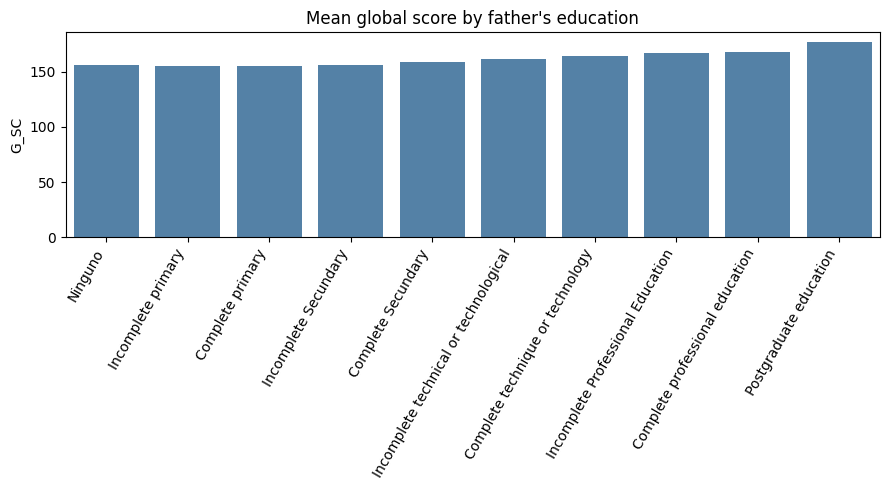

In [4]:

def anova_eta(data, col, by):
    d = data[[col, by]].dropna()
    groups = [g[col].values for _, g in d.groupby(by, observed=True)]
    f, p = stats.f_oneway(*groups)
    gm = d[col].mean()
    ssb = sum(len(g)*(g.mean()-gm)**2 for g in groups)
    sst = ((d[col]-gm)**2).sum()
    return dict(n=len(d), F=round(f,1), p=p, eta_sq=round(ssb/sst,3))

for by in ['EDU_FATHER_C','EDU_MOTHER_C']:
    print(by, anova_eta(df, 'G_SC', by))
    d = df[[by,'G_SC']].dropna()
    print('Spearman:', stats.spearmanr(d[by].cat.codes, d['G_SC']))
    display(df.groupby(by, observed=True)['G_SC'].agg(['count','mean','std']).round(1))

plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='EDU_FATHER_C', y='G_SC', order=edu_order, errorbar=None, color='steelblue')
plt.xticks(rotation=60, ha='right')
plt.title("Mean global score by father's education")
plt.xlabel('')
plt.tight_layout()
plt.savefig('figure1.png', dpi=200, bbox_inches='tight')
plt.show()

Students whose father has postgraduate education average 177.0, compared with 158.8 for complete secondary, a gap of 18.2 points. For mothers it is 175.6 vs 158.5 (17.1 points). Eta-squared is 0.077 for fathers and 0.075 for mothers, a medium effect: each explains about 8% of the differences in scores. Parents' education is related to scores, but this does not prove it causes higher scores.

Q2: Which stratum does best? I compare G_SC across the six strata with ANOVA, and use Tukey tests to see which pairs are different.

,count,mean,median,std
STRATUM,,,,
Stratum 1,1709,152.4,152.0,21.9
Stratum 2,4029,158.2,158.0,22.3
Stratum 3,4045,163.8,164.0,21.7
Stratum 4,1578,172.0,174.0,21.5
Stratum 5,633,177.4,179.0,21.5
Stratum 6,403,181.5,184.0,21.9


{'n': 12397, 'F': np.float64(286.1), 'p': np.float64(1.4255991296541535e-290), 'eta_sq': np.float64(0.103)}
   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1    group2  meandiff p-adj   lower   upper  reject
----------------------------------------------------------
Stratum 1 Stratum 2   5.8465    0.0  4.0455  7.6474   True
Stratum 1 Stratum 3  11.4625    0.0  9.6626 13.2624   True
Stratum 1 Stratum 4  19.6497    0.0 17.4716 21.8278   True
Stratum 1 Stratum 5  25.0342    0.0 22.1314  27.937   True
Stratum 1 Stratum 6  29.1583    0.0 25.7035 32.6131   True
Stratum 2 Stratum 3    5.616    0.0  4.2274  7.0046   True
Stratum 2 Stratum 4  13.8032    0.0 11.9505  15.656   True
Stratum 2 Stratum 5  19.1877    0.0 16.5204 21.8551   True
Stratum 2 Stratum 6  23.3119    0.0 20.0524 26.5713   True
Stratum 3 Stratum 4   8.1872    0.0  6.3355 10.0389   True
Stratum 3 Stratum 5  13.5717    0.0 10.9051 16.2384   True
Stratum 3 Stratum 6  17.6958    0.0  14.437 20.9547   True
Stratum

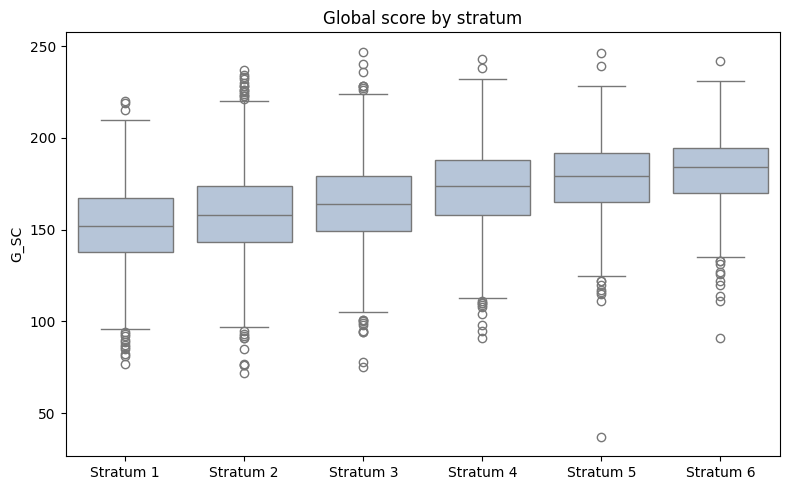

In [5]:
d = df.dropna(subset=['STRATUM'])
display(d.groupby('STRATUM')['G_SC'].agg(['count','mean','median','std']).round(1))
print(anova_eta(df, 'G_SC', 'STRATUM'))
print(pairwise_tukeyhsd(d['G_SC'], d['STRATUM']).summary())

plt.figure(figsize=(8, 5))
sns.boxplot(data=d, x='STRATUM', y='G_SC', order=sorted(d['STRATUM'].unique()), color='lightsteelblue')
plt.title('Global score by stratum')
plt.xlabel('')
plt.tight_layout()
plt.savefig('figure2.png', dpi=200, bbox_inches='tight')
plt.show()

Stratum 6 has the highest average (181.5) and Stratum 1 the lowest (152.4), a gap of 29.2 points (eta-squared = 0.103). Every pair of strata is significantly different. The closest pair is Strata 5 and 6 (adjusted p = 0.037). Tukey tests assume equal variances, and the Levene test below (p = 0.040) shows they are a little unequal. The Welch ANOVA below is still significant, so the overall difference holds, but I read the result for Strata 5 and 6 with care.

Q3: How does each gender do on the global score? I use a Welch t-test, a 95% confidence interval and Cohen's d, and then compare each subject.

In [6]:
display(df.groupby('GENDER')['G_SC'].agg(['count','mean','median','std']).round(2))

m = df.loc[df.GENDER=='M','G_SC']; f = df.loc[df.GENDER=='F','G_SC']
t, p = stats.ttest_ind(m, f, equal_var=False)

n1, n2 = len(m), len(f)
sp = np.sqrt(((n1-1)*m.var() + (n2-1)*f.var()) / (n1+n2-2))
d_cohen = (m.mean()-f.mean()) / sp

se = np.sqrt(m.var()/n1 + f.var()/n2)
diff = m.mean()-f.mean()
welch_df = (m.var()/n1 + f.var()/n2)**2 / ((m.var()/n1)**2/(n1-1) + (f.var()/n2)**2/(n2-1))
critical = stats.t.ppf(0.975, welch_df)
print(f'diff={diff:.2f}, t={t:.2f}, df={welch_df:.1f}, p={p:.2g}, 95% CI [{diff-critical*se:.2f}, {diff+critical*se:.2f}], d={d_cohen:.3f}')

rows = []
for c in num:
    a = df.loc[df.GENDER=='M', c]; b = df.loc[df.GENDER=='F', c]
    rows.append([c, round(a.mean(),1), round(b.mean(),1),
                 round((a.mean()-b.mean())/np.sqrt(((len(a)-1)*a.var()+(len(b)-1)*b.var())/(len(a)+len(b)-2)),2)])
display(pd.DataFrame(rows, columns=['score','male','female','cohen_d']).set_index('score'))

,count,mean,median,std
GENDER,,,,
F,5043,161.28,162.0,22.33
M,7368,163.69,164.0,23.58


diff=2.41, t=5.78, df=11207.2, p=7.8e-09, 95% CI [1.59, 3.23], d=0.105


,male,female,cohen_d
score,,,
MAT_S11,66.0,61.9,0.34
CR_S11,60.7,60.9,-0.02
CC_S11,61.2,60.0,0.12
BIO_S11,65.1,62.3,0.26
ENG_S11,62.0,61.5,0.04
QR_PRO,81.2,71.9,0.42
CR_PRO,62.8,61.3,0.05
CC_PRO,59.6,58.6,0.04
ENG_PRO,68.2,66.5,0.06


Men average 163.69 and women average 161.28, a difference of 2.41 points (95% CI 1.59 to 3.23, p < 0.001). The effect is very small (Cohen's d is about 0.10), so significant does not mean large. Men score higher in quantitative reasoning (81.2 vs 71.9) and women score higher in written communication (56.6 vs 51.7). This does not show that gender causes the difference.

Q4: What else is interesting? I look at how high school scores relate to the final score, and at school type, SISBEN and academic program.

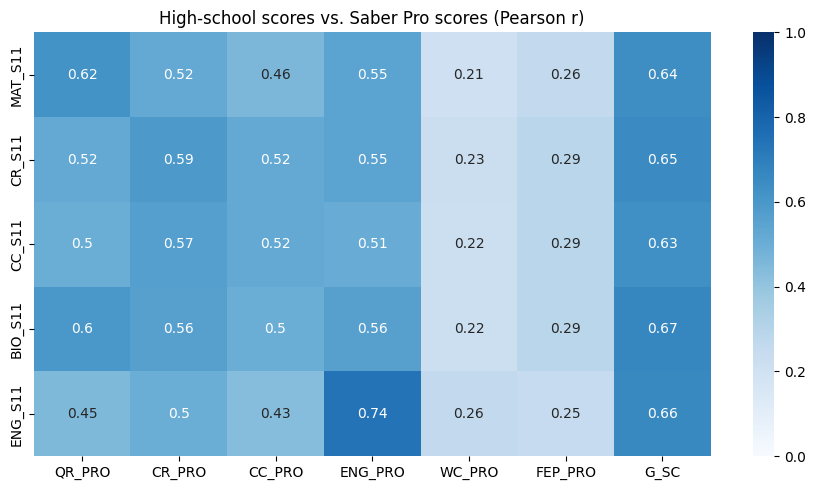

R2 (Saber 11 -> G_SC): 0.609


,count,mean
SCHOOL_NAT,,
PRIVATE,6565,168.2
PUBLIC,5846,156.5


,count,mean
SISBEN,,
Esta clasificada en otro Level del SISBEN,96,166.1
It is not classified by the SISBEN,7534,167.5
Level 1,2057,152.7
Level 2,2120,155.9
Level 3,583,161.0


,count,mean
ACADEMIC_PROGRAM,,
CHEMICAL ENGINEERING,1000,176.7
ELECTRIC ENGINEERING,278,174.0
ELECTRONIC ENGINEERING,849,166.9
MECHANICAL ENGINEERING,1135,166.1
CIVIL ENGINEERING,3320,161.1
INDUSTRIAL ENGINEERING,5318,159.0


In [7]:
targets = pro + ['G_SC']
corr = df[hs + targets].corr().loc[hs, targets].round(2)
plt.figure(figsize=(9, 5))
sns.heatmap(corr, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title('High-school scores vs. Saber Pro scores (Pearson r)')
plt.tight_layout()
plt.savefig('figure3.png', dpi=200, bbox_inches='tight')
plt.show()

print('R2 (Saber 11 -> G_SC):', round(smf.ols('G_SC ~ '+'+'.join(hs), data=df).fit().rsquared, 3))

display(df.groupby('SCHOOL_NAT')['G_SC'].agg(['count','mean']).round(1))
display(df.groupby('SISBEN')['G_SC'].agg(['count','mean']).round(1))
prog = df.groupby('ACADEMIC_PROGRAM')['G_SC'].agg(['count','mean']).round(1)
display(prog[prog['count']>=250].sort_values('mean', ascending=False))

In [8]:
import statsmodels.stats.oneway as ow
for by in ['EDU_FATHER_C','EDU_MOTHER_C','STRATUM']:
    x = df.dropna(subset=[by]); g = [v['G_SC'].values for _, v in x.groupby(by, observed=True)]
    lev = stats.levene(*g, center='median').pvalue
    w = ow.anova_oneway(g, use_var='unequal', welch_correction=True)
    print(by, 'Levene p =', round(lev,4), '| Welch F =', round(w.statistic,1), ', p =', w.pvalue)

d2 = df.dropna(subset=['STRATUM','EDU_FATHER_C','EDU_MOTHER_C']).copy()
d2['EF'] = d2.EDU_FATHER_C.astype(str); d2['EM'] = d2.EDU_MOTHER_C.astype(str)
r = smf.ols('G_SC ~ C(STRATUM)+C(EF)+C(EM)+C(GENDER)', data=d2).fit()
print('Joint R2 =', round(r.rsquared,3), ', n =', int(r.nobs))

EDU_FATHER_C Levene p = 0.0747 | Welch F = 109.9 , p = 6.725963179629756e-164
EDU_MOTHER_C Levene p = 0.0923 | Welch F = 105.8 , p = 8.100041285193645e-131
STRATUM Levene p = 0.0399 | Welch F = 288.3 , p = 1.0001804941560055e-241
Joint R2 = 0.135 , n = 11488


High school scores are strongly related to the final global score (r = 0.63 to 0.67). The five Saber 11 scores together explain about 61% of the variation in G_SC in this sample. This shows fit, not prediction. Stratum, both parents' education and gender together explain only about 13.5% of the variation (n = 11,488). Private-school graduates average 168.2 and public-school graduates average 156.5. SISBEN Level 1 students average 152.7. Among programs with at least 250 students, Chemical Engineering is highest (176.7) and Industrial Engineering lowest (159.0); these are raw averages, not a ranking of teaching quality.

Duplicate ID check. Some rows share a Saber Pro ID, so they may not be independent. I rerun the main comparisons keeping only the first row for each ID, and then only the last row. The results are exploratory, because students in the same school or university can be alike, and the data are observational.

In [9]:
def key_results(data):
    men = data.loc[data.GENDER=='M','G_SC']
    women = data.loc[data.GENDER=='F','G_SC']
    means = data.groupby('STRATUM')['G_SC'].mean()
    return {'n':len(data), 'gender_gap':men.mean()-women.mean(),
            'stratum_6_minus_1':means['Stratum 6']-means['Stratum 1'],
            'father_eta_sq':anova_eta(data,'G_SC','EDU_FATHER_C')['eta_sq'],
            'mother_eta_sq':anova_eta(data,'G_SC','EDU_MOTHER_C')['eta_sq']}
sensitivity = pd.DataFrame({
    'All supplied records':key_results(df),
    'One per Saber Pro ID (first)':key_results(df.drop_duplicates('Cod_SPro',keep='first')),
    'One per Saber Pro ID (last)':key_results(df.drop_duplicates('Cod_SPro',keep='last'))
}).T
display(sensitivity.round(3))


,n,gender_gap,stratum_6_minus_1,father_eta_sq,mother_eta_sq
All supplied records,12411.0,2.413,29.158,0.077,0.075
One per Saber Pro ID (first),12395.0,2.392,29.124,0.077,0.075
One per Saber Pro ID (last),12395.0,2.392,29.124,0.077,0.075


The results barely change: the gender gap is about 2.4, the Stratum 6 minus Stratum 1 gap is about 29.1, and the eta-squared values are the same.

Recommendations. Pilot English and quantitative tutoring, with outreach to low-stratum and public-school students, and choose who gets a place by each student's own test results. Test any early-warning screen on new students before using it. Randomly assign eligible students to tutoring now or to a wait-list, and compare test results, retention and cost per student. This dataset has no costs or program results, so it cannot show cost effectiveness. Program differences should be checked against entry scores and student background before judging teaching quality.

## Data Source

De La Hoz, Enrique. “Data of Academic Performance Evolution for Engineering Students.” Mendeley Data, version 1, 2020, https://doi.org/10.17632/83tcx8psxv.1.